In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from gensim.models import Word2Vec , FastText
from gensim.utils import simple_preprocess

In [3]:
sentences = [
    "Köpek çok tatlı bir hayvandır" , 
    "Köpekler evcil hayvanlardır" , 
    "Kediler genellikle bağımsız hareket etmeyi severler" , 
    "Köpekler sadık ve dost canlısı hayvanlardır" , 
    "Hayvanlar insanlar için iyi arkadaşlardır"
]

In [4]:
tokinezed_sentences = [simple_preprocess(sentence) for sentence in sentences]

In [5]:
tokinezed_sentences

[['köpek', 'çok', 'tatlı', 'bir', 'hayvandır'],
 ['köpekler', 'evcil', 'hayvanlardır'],
 ['kediler', 'genellikle', 'bağımsız', 'hareket', 'etmeyi', 'severler'],
 ['köpekler', 'sadık', 've', 'dost', 'canlısı', 'hayvanlardır'],
 ['hayvanlar', 'insanlar', 'için', 'iyi', 'arkadaşlardır']]

In [6]:
word2_vec_model = Word2Vec(sentences=tokinezed_sentences , vector_size=50 , window=5 , min_count=1 , sg=0)

In [8]:
fast_text_vec_model = FastText(sentences=tokinezed_sentences , vector_size=50 , window=5 , min_count=1 , sg=0)

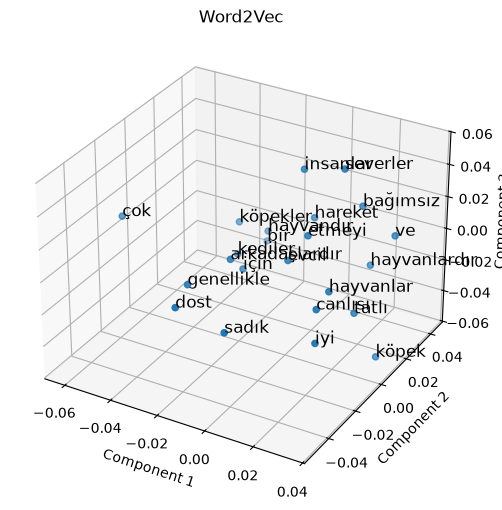

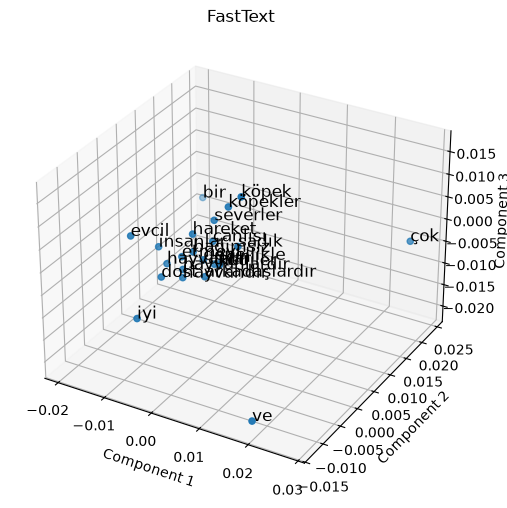

In [11]:
def plot_word_embedding(model , title) : 

    word_vectors = model.wv

    words = list(word_vectors.index_to_key)[:1000]
    vectors = [word_vectors[word] for word in words]

    #PCA

    pca = PCA(n_components=3)
    reduced_vectors = pca.fit_transform(vectors)

    #3D gorsellestirme

    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(111 , projection="3d")

    ax.scatter(reduced_vectors[: , 0] , reduced_vectors[: , 1] , reduced_vectors[: , 2])

    for i , word in enumerate(words):
        ax.text(reduced_vectors[i , 0] , reduced_vectors[i,1] , reduced_vectors[i,2] , word , fontsize=12)

    ax.set_title(title)
    ax.set_xlabel("Component 1") 
    ax.set_ylabel("Component 2")
    ax.set_zlabel("Component 3")
    plt.show()


plot_word_embedding(word2_vec_model , "Word2Vec")
plot_word_embedding(fast_text_vec_model , "FastText")